In [ ]:
import sys
from SPARQLWrapper import SPARQLWrapper, JSON


endpoint_url = "https://dbpedia.org/sparql"


def get_person_info(entity_uri):
    query = f"""
    SELECT ?predicate ?object WHERE {{
        <{entity_uri}> ?predicate ?object .
        FILTER (?predicate != <http://www.w3.org/1999/02/22-rdf-syntax-ns#type>)  # 排除 rdf:type
        FILTER (?predicate = <http://dbpedia.org/property/birthDate> || 
                ?predicate = <http://dbpedia.org/property/nationality> || 
                ?predicate = <http://dbpedia.org/property/occupation> ||
                ?predicate = <http://dbpedia.org/property/deathDate> || 
                ?predicate = <http://dbpedia.org/property/field> || 
                ?predicate = <http://dbpedia.org/property/works>)
    }}
    """
    return get_results(endpoint_url, query)


def get_results(endpoint_url, query):
    user_agent = "DBpedia-example Python/%s.%s" % (sys.version_info[0], sys.version_info[1])
    sparql = SPARQLWrapper(endpoint_url, agent=user_agent)
    

    sparql.setQuery(query)
    

    sparql.setReturnFormat(JSON)
    
 
    return sparql.query().convert()


entity_uri = "http://dbpedia.org/resource/Barack_Obama"


results = get_person_info(entity_uri)

# 打印查询结果
for result in results["results"]["bindings"]:
    predicate = result["predicate"]["value"]
    object_value = result["object"]["value"]
    print(f"Predicate: {predicate}\nObject: {object_value}\n")


Predicate: http://dbpedia.org/property/birthDate
Object: 1961-08-04

Predicate: http://dbpedia.org/property/occupation
Object: 

Predicate: http://dbpedia.org/property/occupation
Object: Politician

Predicate: http://dbpedia.org/property/occupation
Object: author

Predicate: http://dbpedia.org/property/occupation
Object: lawyer



In [ ]:

def get_location_info(entity_uri):
    query = f"""
    SELECT ?predicate ?object WHERE {{
        <{entity_uri}> ?predicate ?object .
        FILTER (?predicate != <http://www.w3.org/1999/02/22-rdf-syntax-ns#type>)  # 排除 rdf:type
        FILTER (?predicate = <http://dbpedia.org/ontology/capital> || 
                ?predicate = <http://dbpedia.org/ontology/populationTotal> || 
                ?predicate = <http://dbpedia.org/ontology/areaTotal> || 
                ?predicate = <http://dbpedia.org/ontology/region>)
    }}
    """
    return get_results(endpoint_url, query)


entity_uri = "http://dbpedia.org/resource/China"


results = get_location_info(entity_uri)


for result in results["results"]["bindings"]:
    predicate = result["predicate"]["value"]
    object_value = result["object"]["value"]
    print(f"Predicate: {predicate}\nObject: {object_value}\n")


Predicate: http://dbpedia.org/ontology/populationTotal
Object: 1410539758

Predicate: http://dbpedia.org/ontology/capital
Object: http://dbpedia.org/resource/Beijing



In [ ]:
import sys
from SPARQLWrapper import SPARQLWrapper, JSON

# 设置 DBpedia 的 SPARQL 查询接口 URL
endpoint_url = "https://dbpedia.org/sparql"


def get_all_triples(entity_uri):
    query = f"""
    SELECT ?predicate ?object WHERE {{
        <{entity_uri}> ?predicate ?object .
        FILTER (lang(?object) = "en")  # 确保对象是英文
    }}
    """
    return get_results(endpoint_url, query)


def get_results(endpoint_url, query):
    user_agent = "DBpedia-example Python/%s.%s" % (sys.version_info[0], sys.version_info[1])
    sparql = SPARQLWrapper(endpoint_url, agent=user_agent)
    

    sparql.setQuery(query)

    sparql.setReturnFormat(JSON)
    

    return sparql.query().convert()

# 简化 Predicate 和 Object，提取简化的文字信息
def simplify_uri(uri):
    # 提取简化的属性名称，如 `http://dbpedia.org/ontology/birthDate` -> `birthDate`
    if uri.startswith("http://dbpedia.org/ontology/"):
        return uri.replace("http://dbpedia.org/ontology/", "")
    elif uri.startswith("http://dbpedia.org/property/"):
        return uri.replace("http://dbpedia.org/property/", "")
    elif uri.startswith("http://dbpedia.org/resource/"):
        # 对资源类 URI 进行适当处理（如提取名称）
        return uri.replace("http://dbpedia.org/resource/", "")
    else:
        return uri


entity_uri = "http://dbpedia.org/resource/Barack_Obama"

results = get_all_triples(entity_uri)


triples_text = ""
for result in results["results"]["bindings"]:

    predicate = simplify_uri(result["predicate"]["value"])
    object_value = result["object"]["value"]
    

    triples_text += f"Predicate: {predicate}\nObject: {object_value}\n\n"

# 打印所有三元组关系
print(triples_text)


Predicate: http://www.w3.org/2000/01/rdf-schema#label
Object: Barack Obama

Predicate: http://www.w3.org/2000/01/rdf-schema#comment
Object: Barack Hussein Obama II (/bəˈrɑːk huːˈseɪn oʊˈbɑːmə/ bə-RAHK hoo-SAYN oh-BAH-mə; born August 4, 1961) is an American politician who served as the 44th president of the United States from 2009 to 2017. A member of the Democratic Party, Obama was the first African-American president of the United States. He previously served as a U.S. senator from Illinois from 2005 to 2008 and as an Illinois state senator from 1997 to 2004, and previously worked as a civil rights lawyer before entering politics.

Predicate: name
Object: Barack Obama

Predicate: birthPlace
Object: Honolulu, Hawaii, U.S.

Predicate: signatureAlt
Object: Cursive signature in ink

Predicate: as
Object: former president

Predicate: signature
Object: Barack Obama signature.svg

Predicate: almaMater
Object: 

Predicate: alt
Object: Official portrait. 2012

Predicate: birthName
Object: Bara

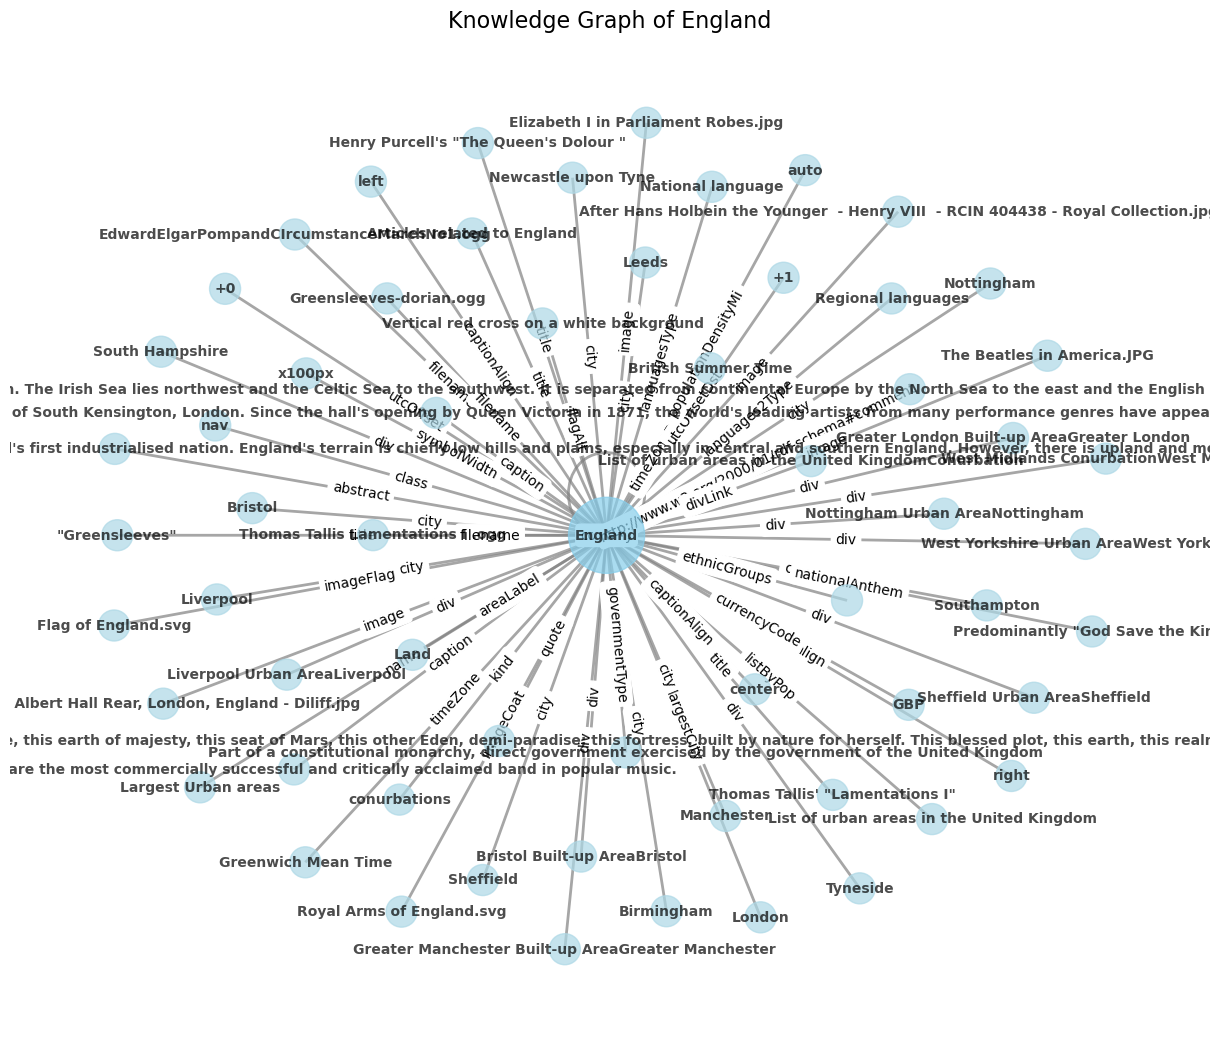

In [38]:
import networkx as nx
import matplotlib.pyplot as plt
from SPARQLWrapper import SPARQLWrapper, JSON
import sys

# 设置 DBpedia 的 SPARQL 查询接口 URL
endpoint_url = "https://dbpedia.org/sparql"

# 定义一个获取查询结果的函数
def get_results(endpoint_url, query):
    user_agent = "DBpedia-example Python/%s.%s" % (sys.version_info[0], sys.version_info[1])
    sparql = SPARQLWrapper(endpoint_url, agent=user_agent)
    
    # 设置查询语句
    sparql.setQuery(query)
    
    # 设置返回结果格式为 JSON
    sparql.setReturnFormat(JSON)
    
    # 执行查询并返回结果
    return sparql.query().convert()

# 查询 England 相关信息
query = """
SELECT ?predicate ?object WHERE {
  <http://dbpedia.org/resource/England> ?predicate ?object .
  FILTER (lang(?object) = "en")  # 确保对象是英文
}
"""

# 获取查询结果
results = get_results(endpoint_url, query)

# 创建图形对象
G = nx.Graph()

# 添加中心节点
G.add_node("England", size=3000, color="skyblue")

# 处理查询结果并添加关系到图中
for result in results["results"]["bindings"]:
    predicate = result["predicate"]["value"]
    object_value = result["object"]["value"]
    
    # 简化 URI
    if predicate.startswith("http://dbpedia.org/ontology/"):
        predicate = predicate.replace("http://dbpedia.org/ontology/", "")
    elif predicate.startswith("http://dbpedia.org/property/"):
        predicate = predicate.replace("http://dbpedia.org/property/", "")
    elif predicate.startswith("http://dbpedia.org/resource/"):
        # 对资源类 URI 进行适当处理
        object_value = object_value.replace("http://dbpedia.org/resource/", "")
        
    # 添加边到图中, relation为Predicate, object为Object
    G.add_edge("England", object_value, label=predicate)

# 设置图的布局
pos = nx.spring_layout(G, seed=42)  # 使用Spring布局

# 设置节点的大小和颜色
node_size = [G.nodes[node]["size"] if "size" in G.nodes[node] else 500 for node in G]
node_color = [G.nodes[node]["color"] if "color" in G.nodes[node] else "lightblue" for node in G]

# 绘制图形
plt.figure(figsize=(12, 10))
nx.draw(G, pos, with_labels=True, node_size=node_size, node_color=node_color, font_size=10, font_weight="bold", edge_color="gray", width=2, alpha=0.7)

# 添加边的标签（关系类型）
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=10)

# 显示图形
plt.title("Knowledge Graph of England", fontsize=16)
plt.axis("off")  # 不显示坐标轴
plt.show()
